# Can a virtual resection predict one patient's post-operative brain network? Structure, function and the distance to cognition

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/AI-assisted-glioma-research/blob/main/notebooks/12_patient_connectome.ipynb)

*In Google Colab, the first code cell clones the public repository and puts its package on the path; Colab's own NumPy, Matplotlib and ipywidgets are used, not the locked versions. The small sub-PAT16 matrices come with the clone. The CANTAB cell of section 3 needs local inputs and shows a notice in Colab.*

**Question:** Does the network model of notebook 11 hold up on a real patient? When the
streamlines that pass through a glioma are removed from the patient's own pre-operative
connectome, do the predicted changes resemble what was measured after surgery?

**Evidence:** Real data, one patient, descriptive. Structural and functional connectivity of
sub-PAT16 from the open Brain Tumor Connectomics data, derived by a local pipeline whose quality
control has **not** been reviewed. Nothing here is a validation, a clinical finding or a
prediction for this patient. Section 3 adds a didactic explorer built on geometric proxies, and
section 4 is explicitly speculative.

**Two tracks.** The motivation, the explanations, the figure readings and the glossary each have a
paragraph for two kinds of reader. Read one or both. The data, the model and the figures are the
same for both.
- *Neuro-oncology and clinical track:* what the matrices say about this patient's tumour, the
  operation and the six-month scan, and why none of it is yet a surgical or cognitive result.
- *Data-analysis and modelling track:* how each matrix is built, what the linear model and its
  nulls can and cannot detect, and what would have to change before the comparison is a test.

This is the real-data companion of notebook 11, which remains the synthetic, checkable teaching
core. Scientific functions live in `glioma_ai.connectome`, `glioma_ai.connectome_figures` and
`glioma_ai.connectome_interactive`. Runs on CPU in a few seconds from the small tracked matrices;
no image, tractogram or data download is needed. The explorer in section 3 needs a running kernel
with the `notebooks` dependency group; the static figures are produced either way.

## Motivation: from one patient's scans to a testable network claim

Notebook 11 showed, on a constructed slice, how a tumour that infiltrates white matter and a
resection that removes it could change a network's structure and its modelled correlated activity.
Every number there followed from rules written in code. Here the same chain meets measurements: a
patient scanned with diffusion MRI (dMRI) and resting-state functional MRI (fMRI) before surgery
and again about six months after it.

**Neuro-oncology and clinical track.** Surgeons already think in networks. Awake mapping, subcortical
stimulation and tractography exist because the cost of a resection is not only the cortex removed
but also the fibres cut on the way. A recent review associates connectome- and tractography-guided
resection with tract preservation, postoperative cognition and extent of resection
([Tykocki and Rakasz 2026](https://doi.org/10.1007/s10143-025-04081-0)). In 63 patients, presurgical
structural connectivity of the default-mode and frontoparietal networks predicted cognitive
impairment three months after surgery better than tumour location alone
([Smolders et al. 2025](https://doi.org/10.1093/braincomms/fcaf346)). In 78 patients with
language-critical gliomas, frontal tract segments could be resected without permanent
postoperative language deficits, whereas resection of parietal and temporal segments predicted them
([Muir et al. 2025](https://doi.org/10.1227/neu.0000000000003792)). Those are cohort findings. This
notebook asks a narrower question about one patient: if we pretend we know which fibres the
operation removed, does the six-month scan look like the prediction? It does not. Sections 1 and 2
show why that failure is informative, and none of it bears on the care this patient received.

**Data-analysis and modelling track.** The structure–function problem has a standard formulation.
Build a structural matrix from tractography, put a dynamical model on it, and compare the model's
correlations with measured FC ([Honey et al. 2009](https://doi.org/10.1073/pnas.0811168106)). In
this cohort, [Aerts et al. (2020)](https://doi.org/10.1016/j.neuroimage.2020.116738) did this with
The Virtual Brain, and a 2025 study fitted a nonlinear oscillator (Hopf) whole-brain model to glioma
patients' FC and found larger influence of interregional interactions than in controls
([Alexandersen et al. 2025](https://doi.org/10.1162/netn_a_00426)). There is a deeper warning: in
networks whose wiring is known exactly, the connectome often does not pin down the dynamics until
some activity is also recorded ([Beiran and Litwin-Kumar 2025](https://doi.org/10.1038/s41593-025-02080-4)).
Here the model is deliberately the simplest one with an exact answer, so every failure can be traced
to data, preprocessing or model, not to an optimiser.

## Data, licence and what was derived

- **Source.** sub-PAT16 of the Brain Tumor Connectomics data (Aerts, Marinazzo and colleagues):
  pre-operative session from [OpenNeuro ds001226 v5.0.0](https://doi.org/10.18112/openneuro.ds001226.v5.0.0)
  and post-operative session from [ds002080 v4.0.0](https://doi.org/10.18112/openneuro.ds002080.v4.0.0),
  released under **CC0**. The cohort and its modelling are described by
  [Aerts et al. (2018)](https://doi.org/10.1523/ENEURO.0083-18.2018),
  [Aerts et al. (2020)](https://doi.org/10.1016/j.neuroimage.2020.116738) and
  [Aerts et al. (2022)](https://doi.org/10.1038/s41597-022-01806-4). Per the dataset, the
  post-operative scan is about six months after surgery; that interval is not used here.
- **Upstream processing** (the investigator's local `glioma-brain-digital-twin` project, not in
  this repository): FreeSurfer `aparc+aseg` per session; QSIPrep and MRtrix3 multi-shell CSD,
  10 million iFOD2 streamlines per session with
  [SIFT2](https://doi.org/10.1016/j.neuroimage.2015.06.092) weights, all moved to each
  session's native T1w space; a TumorSynth tumour mask on the pre-operative T1w; and resting-state
  FC from fMRIPrep outputs (confound regression, 0.01–0.1 Hz band-pass, scrubbing at framewise
  displacement > 0.5 mm, Pearson correlation).
- **Derived** by the explicit step `make pat16-connectome`
  (`scripts/derive_pat16_connectome.py`, kept in the development repository because it reads the
  local upstream derivatives):
  - structural matrices between the 82
    [Desikan–Killiany](https://doi.org/10.1016/j.neuroimage.2006.01.021) cortical and
    subcortical regions, with an endpoint assigned to the region containing it, or else to the
    nearest region voxel within 4 mm; and
  - the part of the pre-operative weight carried by streamlines passing through the tumour mask.
  The upstream structural matrices were not reused: they treated every `aparc+aseg` label as a
  node, including white matter and ventricles. That left only 15% of the weight between the 82
  regions. To check the new reader, it rebuilt those upstream matrices, and the comparison with
  MRtrix3 `tck2connectome` is printed below. FC matrices are taken unchanged after checking that
  they follow from the cleaned time series.
- **Tracked.** The investigator authorised tracking these small CC0-derived files in
  `data/derived/sub-PAT16/`: matrices as TSV, `regions.tsv` with centroids and tumour overlap,
  and `provenance.json` with input and file SHA-256 hashes. On 14 October 2026 the investigator
  also authorised publishing them in the public repository, with the upstream QC still
  unreviewed. Images, tractograms, demographics and the upstream derivatives stay outside Git.

## AI contribution and verification

**Question.** Can notebook 11's chain (tumour → lost connections → model functional
connectivity) be run on a real patient's pre- and post-operative data, and how close are its
predictions?

**AI contribution.**
- *Trained imaging AI*: none in this repository. The upstream tumour mask came from TumorSynth,
  a trained segmentation model run in the upstream project; its output has not been reviewed.
- *Generative research assistance* (development only; records in `docs/ai-use/`): on
  10 October 2026 a Cursor agent (model and settings not captured) did the inspection of the
  upstream derivatives, proposed rebuilding the structural matrices, and wrote the track reader
  and endpoint assignment, the analyses, figures, tests and this text
  ([record](../../docs/ai-use/2026-10-10-notebook-14b-patient-connectome.md); the notebook was then
  numbered 14b). On 14 October 2026 Antigravity added the Colab setup
  ([record](../../docs/ai-use/2026-10-14-publish-notebooks-11-12.md)). On 15 October 2026 a Cursor
  agent (reported as Claude Opus 5.5; settings not captured) added the two reading tracks, the
  glossary, the homotopic summary, the resection-size and location explorer of section 3, the
  speculative section 4, the expanded limits and the reference list
  ([record](../../docs/ai-use/2026-10-15-notebook-12-tracks.md)). The analyses of sections 1 and 2
  were not changed.
- *Conventional code* (rerun every time, no model): loading, the linear model, nulls, the sphere
  proxies and figures. Rebuilding the notebook calls no LLM.

**Investigator choices.** The investigator asked for real, openly available data to make the
teaching notebooks more convincing. They chose companion notebooks that leave the synthetic
ones intact, named sub-PAT16 (with its CANTAB scores) as the first case, and authorised tracking
the small CC0-derived matrices. On 15 October 2026 they asked for two reading tracks, an interactive
scenario of resection size and location as an introduction to the CANTAB scores, a speculative
section on connectomics and the analog-cognition framework of
[Miller, Brincat and Roy (2026)](https://doi.org/10.1523/JNEUROSCI.0711-26.2026), expanded limits
and 2025–2026 references. Within that scope, the assistant chose:
- *Virtual resection*: remove every streamline that passes through the pre-operative tumour mask.
  The mask stands in for the resection, but it is not the post-operative cavity.
- *Model*: notebook 11's linear model, with weights
  $W=\log(1+\text{SIFT2 weight})$ divided by the pre-operative spectral radius, and $g=0.8$.
  The log is a stated compression of heavy-tailed weights, not a fitted choice.
- *Nulls*: region labels shuffled, for structure–function agreement; and the same
  tumour-crossing fractions placed on random connected pairs, for the virtual resection.
- *Explorer (section 3)*: a sphere of chosen centre and radius, with two geometric proxies because
  the tractogram is not in Git: regions whose centroid lies inside are removed, and connections whose
  straight centroid-to-centroid segment passes through it are cut. The proxy is checked once against
  the streamlines measured through the tumour mask. The assignment of CANTAB measures to regions is
  an unsourced assumption, as in notebook 11.

**Verification.**
- *Reader*: the memory-mapped `.tck` reader matches nibabel on test files and across chunk
  boundaries. Rebuilding the upstream all-label matrices reproduces MRtrix3 `tck2connectome` with
  edge correlation above 0.9998 in both sessions (printed below).
- *Files*: SHA-256 hashes of the tracked files match `provenance.json`, and the provenance
  contains no local paths. The tumour-crossing weight never exceeds the pre-operative weight.
- *Model*: the stability and exactness checks of notebook 11 apply unchanged.
- *Explorer*: tests check the point-to-segment distance, that radius 0 changes nothing, that a
  larger sphere never restores weight, and that every region named in the assumed table exists.
- *References*: on 15 October 2026 every DOI below resolved in Crossref with the cited title,
  first author, journal and year; summaries follow the PubMed or publisher abstracts.
- *Not verified*: everything the upstream checklist lists (surfaces, registrations, eddy
  correction, tractography, tumour mask, parcellation after surgery). Nor are test–retest
  variability for this patient, the identity of the resected tissue, or any relation to cognition.

**Evidence status.** Real-data observations from one patient, with upstream QC pending.
Agreement or disagreement with the model is descriptive and cannot be generalised. Section 3's
explorer is a geometric teaching device; section 4 is hypothesis.

## Glossary: concepts and definitions for both tracks

Refer back as needed. Symbols are defined again where they are used.

| Term | Neuro-oncology and clinical reading | Data-analysis and modelling definition |
| --- | --- | --- |
| Structural connectome, $S$ | Which brain regions are linked by white-matter fibres, as reconstructed from dMRI. | Symmetric 82 × 82 matrix; $S_{ij}$ is the SIFT2-weighted count of streamlines with one end in region $i$ and the other in $j$ (arbitrary units). |
| Streamline, SIFT2 | A computed path following the dominant fibre direction; not an axon. | Output of iFOD2 tractography; [SIFT2](https://doi.org/10.1016/j.neuroimage.2015.06.092) gives each streamline a weight so that totals better match the diffusion signal. |
| Parcellation (Desikan–Killiany) | 68 cortical gyral regions plus 14 deep grey structures, labelled per session by FreeSurfer. | Node set; endpoints are assigned to the containing region or the nearest region voxel within 4 mm. Labels inside a tumour are unreliable. |
| Functional connectivity (FC), $F$ | How similarly two regions' BOLD signals fluctuate at rest: co-activity, not a fibre. | Pearson correlation of cleaned, band-passed (0.01–0.1 Hz) BOLD time series, TR 2.4 s, about six minutes per session. |
| Homotopic pair | The same region in the left and right hemisphere, e.g. both insulae. | 41 of the 3,321 region pairs. |
| Structure–function agreement | Does the wiring explain which regions co-fluctuate? | Correlation over all region pairs between model FC and measured FC. |
| Coupling $g$ | How strongly regions drive each other in the model; not a clinical quantity. | Scalar in $[0,1)$ multiplying $W$; stability requires $g\,\rho(W)<1$. |
| Virtual resection | "What if exactly the fibres through the tumour were cut?" | $S^{\text{virtual}}=S^{\text{pre}}-S^{\text{tumour}}$. |
| Tumour-crossing share $f_{ij}$ | Fraction of a connection that ran through the tumour mask. | $f_{ij}=S^{\text{tumour}}_{ij}/S^{\text{pre}}_{ij}$. |
| Node strength | How well connected a region is overall. | $k_i=\sum_j S_{ij}$. |
| Global efficiency | How easily, on average, any region reaches any other. | Mean inverse shortest-path length with edge length $1/W_{ij}$ ([Latora and Marchiori 2001](https://doi.org/10.1103/PhysRevLett.87.198701)). |
| Null model | "Would a meaningless version of the same data look as good?" | A reference distribution: shuffled region labels, or tumour shares on random pairs. |
| Regression to the mean | Extreme first measurements tend to be less extreme the second time, even without change. | With noisy FC, $\operatorname{corr}(F^{\text{post}}-F^{\text{pre}},F^{\text{pre}})<0$ arises without any true change. |
| Sphere proxy (section 3) | A crude stand-in for a resection of given size and place. | Remove regions whose centroid is within $r$ of the centre; cut pairs whose straight centroid segment comes within $r$. |
| Assumed domain table | Which regions each CANTAB measure *might* rely on; an assumption, not anatomy. | Five sets of DK regions; the explorer averages retained node strength over each set. |
| Brain waves, bands | Rhythms seen on EEG, MEG or ECoG: roughly delta (1–4 Hz), theta (4–8), alpha (8–13), beta (13–30), gamma (30–80); conventions differ between papers. | Band-limited components of extracellular potentials; far faster than the 0.01–0.1 Hz BOLD band. |
| Travelling wave | A rhythm whose phase moves across the cortex, like a ripple. | Phase that varies systematically with position; planar, rotating or concentric. |
| Ephaptic coupling | Neurons influenced by the electric field of neighbours, without synapses. | Extracellular field acting on membrane potential; see notebook 08. |
| Mixed selectivity | Single neurons respond to combinations of task variables, not to one thing. | Nonlinear conjunctive tuning that raises the dimensionality of population codes. |
| Spatial computing | A hypothesis that alpha/beta patterns act as stencils deciding where in cortex information is expressed. | Spatially patterned low-frequency inhibition gating gamma and spiking ([Lundqvist et al. 2023](https://doi.org/10.1038/s41467-023-36555-4)). |

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def repository_root():
    candidates = (Path.cwd(), *Path.cwd().parents)
    return next((p for p in candidates if (p / "pyproject.toml").is_file()), None)


if IN_COLAB and repository_root() is None:
    checkout = Path("/content/AI-assisted-glioma-research")
    if not checkout.is_dir():
        url = "https://github.com/arvidl/AI-assisted-glioma-research"
        subprocess.run(["git", "clone", "--depth", "1", url, str(checkout)], check=True)
    os.chdir(checkout)
    sys.path.insert(0, str(Path.cwd() / "src"))
if repository_root() is None:
    raise RuntimeError("Open this notebook in a checkout of the repository or in Google Colab.")

In [2]:
import json
import os
from pathlib import Path

from IPython.display import Image, display

from glioma_ai.connectome import load_case
from glioma_ai.connectome_figures import write_connectome_experiment

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
OUTPUT = ROOT / "outputs/notebook12"
case = load_case()
record = write_connectome_experiment(OUTPUT, case=case)
source = case.provenance
qc = source["upstream_qc"]
print(f"Case {source['case']}; licence {source['license']}")
print(f"Upstream QC checklist: {qc['items_checked']} of {qc['items_total']} items checked")
for session, entry in source["sessions"].items():
    check = entry["upstream_all_label_check"]
    print(
        f"{session:>7}: {entry['streamlines']:,} streamlines; "
        f"{100 * entry['assigned_weight_fraction']:.1f}% of SIFT2 weight between the 82 regions; "
        f"{entry['bold']['clean_volumes']}/{entry['bold']['volumes']} clean BOLD volumes "
        f"(TR {entry['bold']['repetition_time_s']} s)"
    )
    print(
        f"         reader check vs tck2connectome (all labels): edge r = "
        f"{check['edge_correlation']:.5f}, totals {check['rebuilt_total']:,.0f} vs "
        f"{check['upstream_total']:,.0f}"
    )
tumour = record["tumour"]
print(
    f"\nTumour mask {tumour['mask_volume_ml']} mL; "
    f"{tumour['preop_weight_through_tumour_percent']}% of pre-op weight passes through it"
)
print(
    "Regions with >10% of voxels inside the mask:",
    ", ".join(tumour["regions_over_10_percent_inside"]),
)

Case sub-PAT16; licence CC0 (BIDS dataset_description.json of the source subset)
Upstream QC checklist: 0 of 37 items checked
  preop: 10,000,000 streamlines; 41.4% of SIFT2 weight between the 82 regions; 157/180 clean BOLD volumes (TR 2.4 s)
         reader check vs tck2connectome (all labels): edge r = 0.99996, totals 6,725,641 vs 6,718,380
 postop: 10,000,000 streamlines; 43.0% of SIFT2 weight between the 82 regions; 160/180 clean BOLD volumes (TR 2.4 s)
         reader check vs tck2connectome (all labels): edge r = 0.99987, totals 6,545,462 vs 6,545,282

Tumour mask 53.3 mL; 10.6% of pre-op weight passes through it
Regions with >10% of voxels inside the mask: R-Thalamus, R-Putamen, R-Pallidum, R-Hippocampus, R-Amygdala, R-bankssts, R-entorhinal, R-fusiform, R-parahippocampal, R-transversetemporal, R-insula


All regions with more than 10% of their voxels inside the tumour mask are in the right
hemisphere: medial and lateral temporal, insular and deep grey matter. The dataset lists the
tumour as fronto-temporal; no frontal region passes the 10% mark here. FreeSurfer labels inside a tumour are unreliable, so these shares
locate the tumour rather than measure lost grey matter.

## 1. Structure and function before surgery

Before asking what surgery changed, we need to know how well this patient's wiring explains this
patient's resting activity at all. If it explains little before surgery, a prediction of change
cannot be expected to do better.

**Neuro-oncology and clinical track.** Two scans of the same brain are compared. dMRI tractography
estimates which regions are joined by fibres and how strongly. Resting-state fMRI records slow BOLD
fluctuations while the patient lies still, and FC records which regions rise and fall together. The
two need not agree. Regions can co-fluctuate through a third region, and a tumour can disturb either
measurement: oedema and mass effect distort tractography, and the tumour can alter neurovascular
coupling and so the BOLD signal. A 2025 study combining both modalities in 41 newly diagnosed glioma
patients detected abnormalities far from the lesion more readily with FC than with structural
measures ([Colpo et al. 2025](https://doi.org/10.1038/s41598-025-22192-y)). Section 1 is the baseline
check: before surgery, how much of this patient's FC follows from the wiring?

**Data-analysis and modelling track.** The model is a noise-driven linear system on the structural
matrix. It has an exact stationary correlation, so its "prediction" of FC has no free parameter
except the global coupling $g$. Agreement is measured as a correlation over 3,321 region pairs, and
it is compared with a null in which the region labels of the structural matrix are shuffled. One
check matters more than the null. If the best agreement occurs at the smallest $g$, the model's
indirect paths add nothing, and $\log(1+S)$ itself predicts FC as well as the model does. The
dashed lines in panel D show exactly that direct comparison.

Symbols:
- $S_{ij}$: SIFT2-weighted streamline sum between regions $i$ and $j$ (arbitrary units).
- $W=\log(1+S)/\rho$, with $\rho$ the largest eigenvalue of the pre-operative $\log(1+S)$.
- $F_{ij}$: measured FC, the Pearson correlation of cleaned BOLD time series.
- Model FC: the exact stationary correlation of $\dot{\mathbf x}=-\mathbf x+gW\mathbf x+\sigma\boldsymbol\xi$
  (notebook 11, section 3).
- Agreement: the correlation, over all 3,321 region pairs, between model and measured FC, as in
  [Honey et al. (2009)](https://doi.org/10.1073/pnas.0811168106).

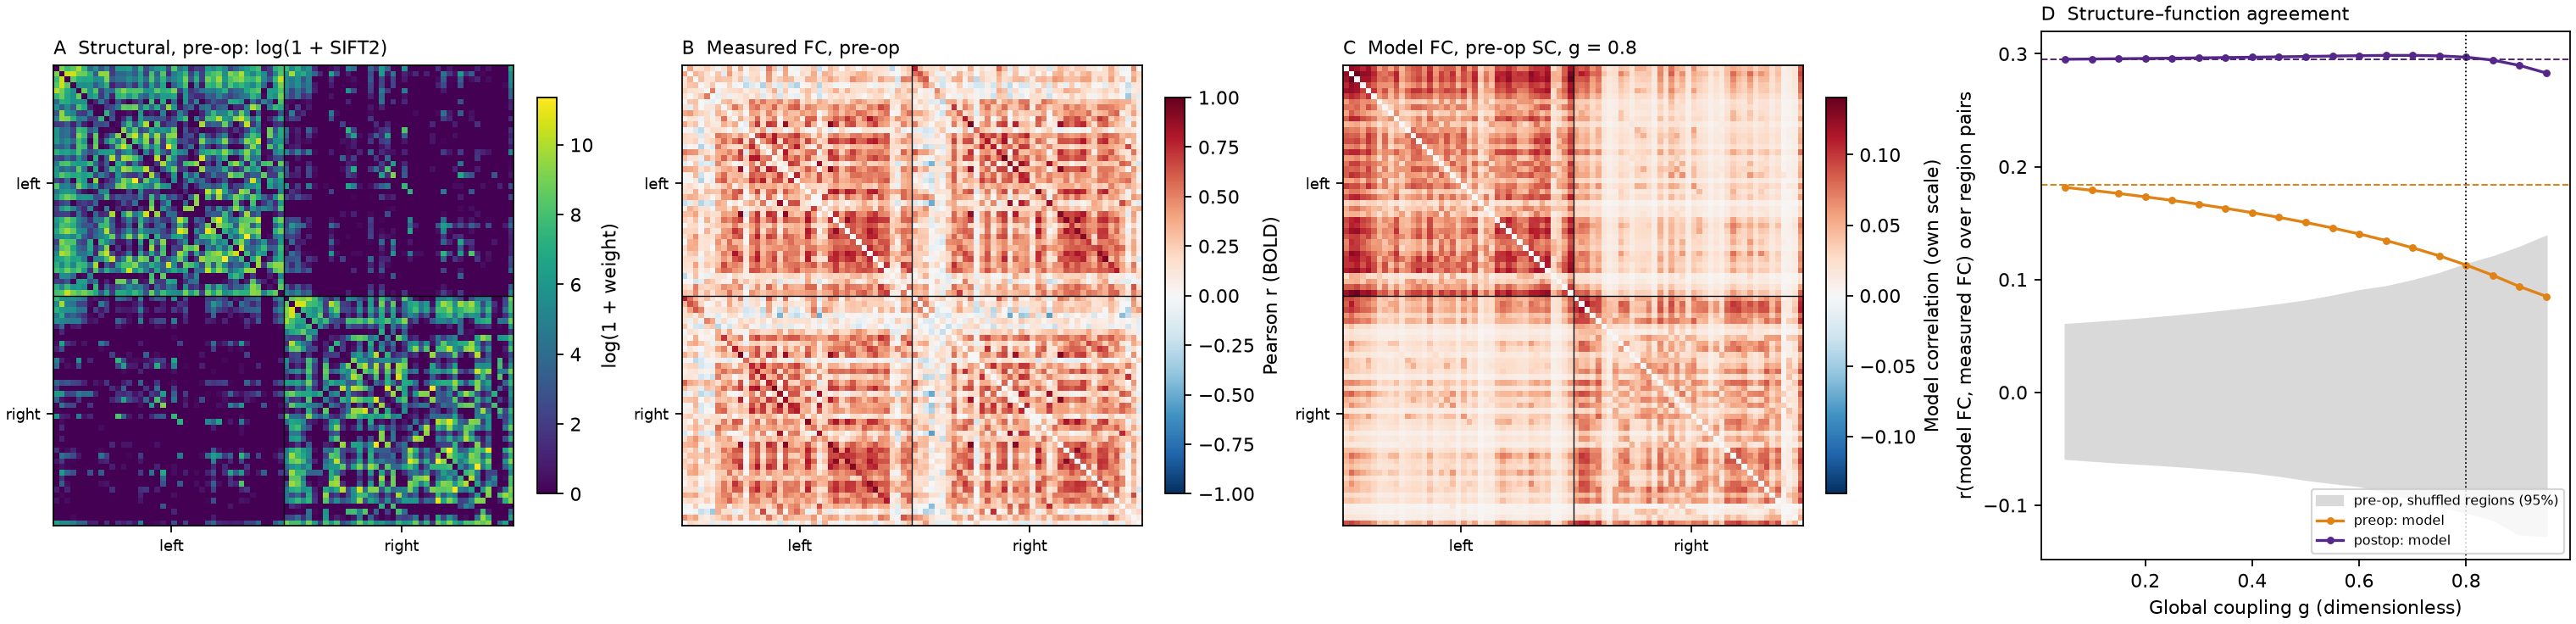

  preop: r at g = 0.8: 0.113; best r 0.182 at g = 0.05; log SC vs FC directly: 0.184
 postop: r at g = 0.8: 0.297; best r 0.299 at g = 0.7; log SC vs FC directly: 0.295
Pre-op shuffled-region null at g = 0.8: 97.5th percentile 0.113
Lower bound on FC sampling error per pair (Fisher z SE): {'preop': 0.081, 'postop': 0.08}


In [3]:
display(Image(filename=str(OUTPUT / "pat16_connectome.png")))
for session, values in record["structure_function"].items():
    print(
        f"{session:>7}: r at g = {record['model']['coupling_g']:g}: {values['r_at_g']:.3f}; "
        f"best r {values['best_r']:.3f} at g = {values['best_g']:g}; "
        f"log SC vs FC directly: {values['direct_r_log_sc_vs_fc']:.3f}"
    )
null = record["preop_shuffled_region_null_at_g"]
print(f"Pre-op shuffled-region null at g = 0.8: 97.5th percentile {null['percentile_97_5']:.3f}")
print("Lower bound on FC sampling error per pair (Fisher z SE):", record["fisher_se_lower_bound"])

**Figure 1 | Structural and functional connectivity of one patient before surgery.**
**A**, $\log(1+S)$ between 82 regions, left hemisphere first (subcortical, then cortical).
**B**, Measured resting-state FC. **C**, Model FC from the matrix in A at $g=0.8$, on its own
colour scale. **D**, Agreement between model and measured FC as a function of $g$, before
(orange) and after (purple) surgery. Dashed lines show the direct correlation of $\log(1+S)$
with FC. The grey band holds 95% of the pre-operative agreement after shuffling region labels.
Real data, one patient, upstream QC pending.

**Reading Figure 1.**
- Agreement is weak. Before surgery it is about 0.1 at $g=0.8$, at the edge of the
  shuffled-region null. It is best at the smallest $g$, where the model FC is just the direct
  structural weight. After surgery it is about 0.3, almost independent of $g$. So in this patient
  the model adds nothing beyond the direct correlation with structural weight.
- The measured FC in B is positive almost everywhere. Global-signal regression was not part of
  the upstream cleaning, which may shift every correlation upward. The model has no such shared
  component.
- About six minutes of BOLD per session give an FC sampling error of at least 0.08 per pair, and
  more given autocorrelation. Part of the difference between sessions is therefore noise.

**Panel by panel, neuro-oncology and clinical track.**
- *A, the wiring.* Two bright squares on the diagonal are the two hemispheres. Each is densely
  connected within itself. The dark off-diagonal squares are left–right connections, which must cross
  the corpus callosum or another commissure. They are sparse here; tractography commonly
  under-reconstructs callosal fibres that fan out laterally. The right temporal and insular rows,
  where the tumour sits, are not obviously empty. Tractography still finds paths through or around
  the mass.
- *B, the co-activity.* Almost every pair is positively correlated, and a faint diagonal stripe in
  the off-diagonal squares marks homotopic pairs (the same region on both sides). The table printed
  below quantifies it. Mirror regions co-fluctuate strongly, as in healthy brains, even though A
  shows few direct fibres between most of them.
- *C, the model.* The model reproduces the hemispheric blocks of A, but its left–right correlations
  are weak, because few fibres join the hemispheres. It cannot produce B's homotopic stripe.
- *D, the verdict.* The orange curve sits barely above the grey band of shuffled brains. Before
  surgery, this patient's wiring explains about 1–3% of the variance in FC over pairs ($r^2$ for $r$
  between 0.1 and 0.18). That is the ceiling against which section 2 must be read.

**Panel by panel, data-analysis and modelling track.**
- *A.* $\log(1+S)$ compresses about four orders of magnitude. 57% of pairs are connected before
  surgery and 64% after (in `pat16_connectome.json`). That difference is already a warning that the
  two sessions' tractography differs in more than the operation.
- *B.* No global-signal regression, so every entry carries a shared positive offset. Because Pearson
  correlation over pairs is invariant to a constant shift, this offset does not change the agreement
  in D. It does affect any reading of absolute FC values.
- *C.* The colour scale is the model's own, at most about 0.13. The model's absolute correlations
  are an order of magnitude smaller than the measured ones, so only the *pattern* is compared, never
  the level.
- *D.* The orange curve decreases monotonically with $g$, and its maximum is at the edge of the grid.
  Indirect paths therefore hurt rather than help. The shuffled-region band widens with $g$, because
  stronger coupling spreads any matrix's structure across all pairs. The post-operative curve is
  flat and close to its dashed line: once again the direct weight carries all the agreement. That
  pre- and post-operative agreement differ (about 0.1 versus 0.3) with one FC per session and a
  sampling error of at least 0.08 per pair is not evidence that surgery improved structure–function
  coupling.

In [4]:
from glioma_ai.connectome import homotopic_summary

kinds = ("homotopic", "other_interhemispheric", "intrahemispheric")
print(f"{'session':<8}{'pair kind':<24}{'pairs':>6}{'mean S':>10}{'mean FC':>9}{'model FC':>10}")
for session, summary in homotopic_summary(case, coupling=0.8).items():
    for kind in kinds:
        row = summary[kind]
        print(
            f"{session:<8}{kind:<24}{row['pairs']:>6}{row['mean_sc']:>10.0f}"
            f"{row['mean_fc']:>9.3f}{row['mean_model_fc']:>10.3f}"
        )
    share = summary["interhemispheric_weight_percent"]
    print(f"{'':<8}interhemispheric share of structural weight: {share:.1f}%\n")

session pair kind                pairs    mean S  mean FC  model FC
preop   homotopic                   41      1079    0.681     0.038
preop   other_interhemispheric    1640        18    0.289     0.026
preop   intrahemispheric          1640      2347    0.297     0.054
        interhemispheric share of structural weight: 1.9%

postop  homotopic                   41      4387    0.673     0.043
postop  other_interhemispheric    1640       119    0.276     0.031
postop  intrahemispheric          1640      2253    0.291     0.051
        interhemispheric share of structural weight: 9.2%



**What the table adds.** Homotopic pairs have much higher measured FC than other left–right pairs,
in both sessions. The model's homotopic correlation is barely above its other interhemispheric
pairs, because it can only pass correlation along fibres, and few are reconstructed between the
hemispheres. The interhemispheric share of structural weight differs several-fold between the two
sessions, while homotopic FC barely changes. Surgery in the right temporal lobe is not expected to
*add* commissural fibres, so this difference most likely reflects tractography and parcellation
differences between sessions.

**Neuro-oncology and clinical track.** Strong mirror-region co-activity with sparse direct fibres is
a familiar result: bilateral coordination survives a great deal of structural variation. For this
patient it means that a model built only on reconstructed fibres misses one of the most prominent
features of resting activity before any surgery is simulated.

**Data-analysis and modelling track.** Two concrete improvements follow. First, test a model that adds
homotopic coupling, or that uses search-light or commissure-specific tractography, and report it as a
variant, not a replacement. Second, treat the change in interhemispheric share between sessions as an
estimate of the measurement's instability. Any structural change of comparable size elsewhere cannot
be attributed to the operation.

## 2. A virtual resection compared with the measured post-operative network

The virtual resection removes from the pre-operative matrix every streamline with any point in
the tumour mask: $S^{\text{virtual}}=S^{\text{pre}}-S^{\text{tumour}}$. For each pair, $f_{ij}$ is
the share of pre-operative weight that passes through the tumour.
[Aerts et al. (2020)](https://doi.org/10.1016/j.neuroimage.2020.116738) compared virtual and
actual post-operative networks in this cohort with The Virtual Brain, a richer nonlinear model,
and reported variable agreement. Here the comparison is made at the level of single connections:
- **Structure:** the measured change $\log_2(S^{\text{post}}/S^{\text{pre}})$ against $f$. A
  pseudo-count of 1 is added, and only pairs with $S^{\text{pre}}\ge10$ are used. If the virtual
  resection were right, points would follow $\log_2(1-f)$.
- **Function:** the model FC change predicted by the virtual resection against the measured FC
  change, compared with the placement null and with the change the model predicts from the
  *measured* post-operative structural matrix.

**Neuro-oncology and clinical track.** The virtual resection is the most generous possible assumption
about the operation. It removes every fibre that touched the tumour mask, as if the cavity were the
mask, resection were complete and nothing else changed. The real situation differs in ways a
neurosurgeon will recognise. The cavity may be smaller or larger than the enhancing or segmented
tumour. Fibres may be displaced rather than destroyed. Oedema resolves, the brain shifts into the
cavity, and gliosis forms. Six months is also long enough for reorganisation. A 2025 review of 34
studies of awake surgery found that most patients had minimal or no cognitive decline, and that many
recovered within three to six months
([Amores-Carrera et al. 2025](https://doi.org/10.1093/nop/npaf075)). Expect the measured structure to
lose less than the virtual resection predicts, and read the size of that gap as information about
these factors.

**Data-analysis and modelling track.** Two predictions are tested, and they fail in different ways.
The structural prediction is a curve, $\log_2(1-f)$, with no free parameter: a connection that ran
entirely through the mask should vanish ($\log_2 0\to-\infty$; the pseudo-count bounds it). The
functional prediction passes the virtual matrix through the model and compares the change in model
FC with the change in measured FC. Two controls separate the effect of *where* the tumour is from the
effect of *how much* weight it removes. The placement null keeps the same crossing fractions on random
pairs. The measured post-operative structural matrix in the model gives the best this model could do
with perfect knowledge of post-operative structure.

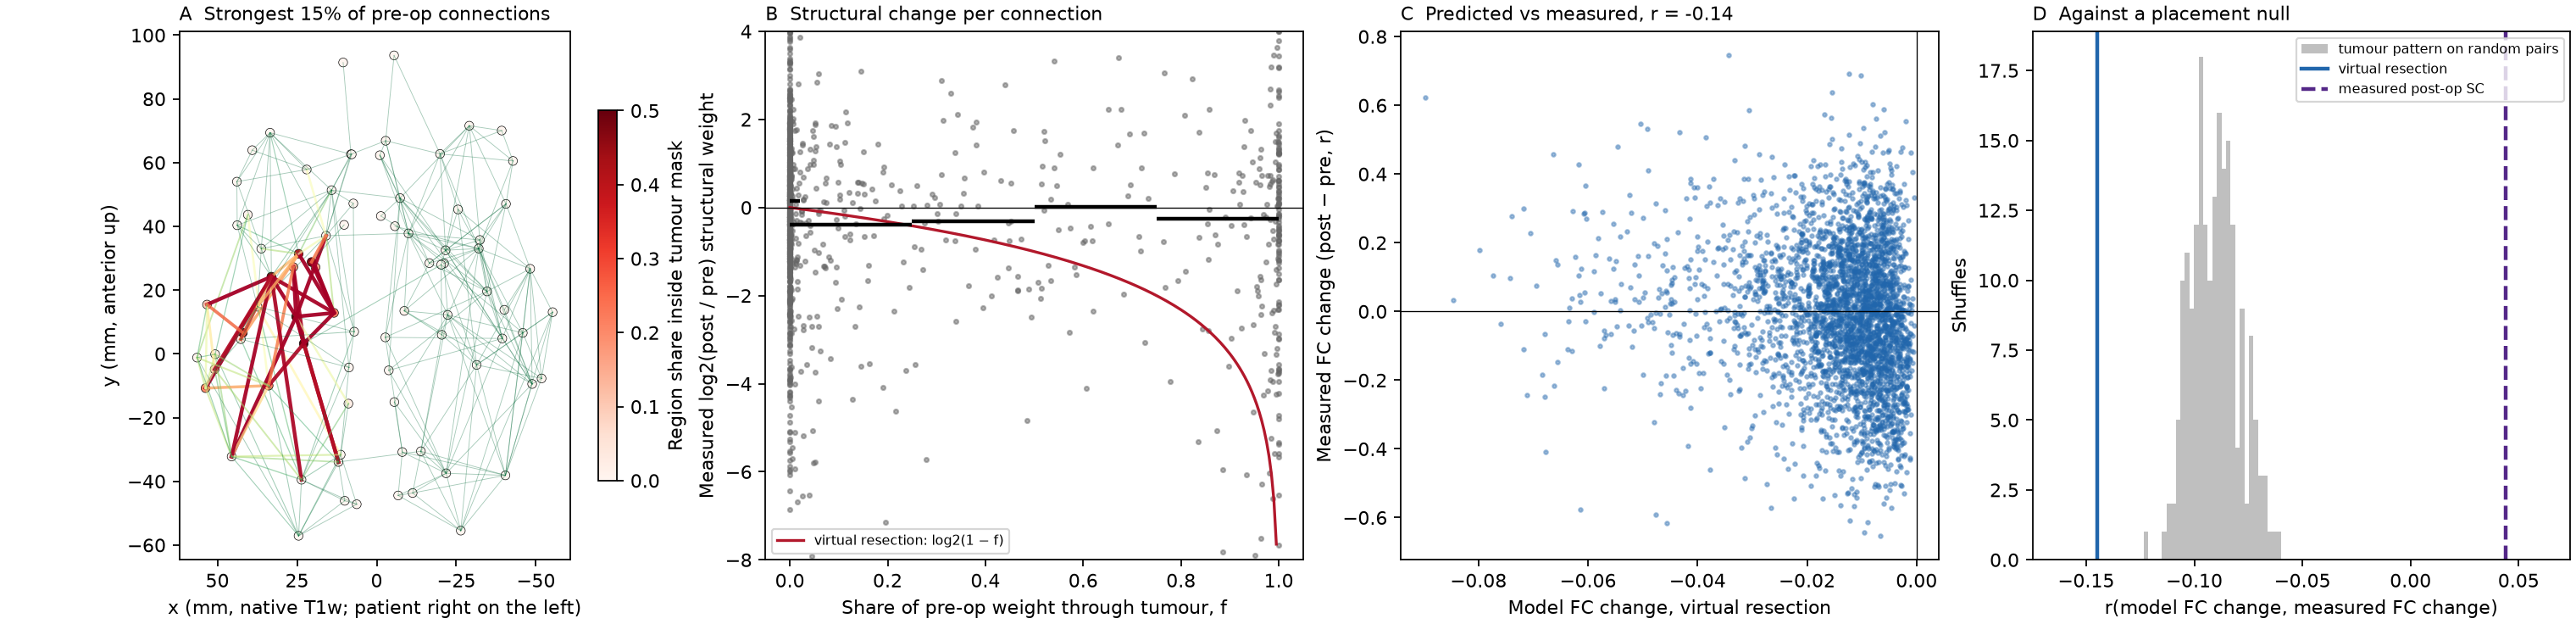

Median measured log2(post/pre) by share of weight through tumour, f:
  f = 0               648 pairs   median +0.14
  0.00 ≤ f < 0.25     258 pairs   median -0.39
  0.25 ≤ f < 0.50      53 pairs   median -0.30
  0.50 ≤ f < 0.75      44 pairs   median +0.01
  f ≥ 0.75            228 pairs   median -0.25
{
 "r_virtual_resection": -0.145,
 "r_measured_postop_sc": 0.044,
 "r_measured_change_vs_preop_fc": -0.205,
 "r_virtual_after_regressing_preop_fc": -0.113,
 "pre_post_fc_similarity_r": 0.699,
 "placement_null": {
  "count": 200,
  "median": -0.09,
  "percentile_97_5": -0.068,
  "p_one_sided_virtual": 1.0
 }
}
Node-strength ratio, virtual vs measured, r = -0.151


In [5]:
display(Image(filename=str(OUTPUT / "pat16_resection.png")))
print("Median measured log2(post/pre) by share of weight through tumour, f:")
for row in record["structural_change_by_crossing"]:
    low, high = row["crossing_fraction"]
    label = (
        "f = 0" if high < 1e-6 else f"{low:.2f} ≤ f < {high:.2f}" if high < 1 else f"f ≥ {low:.2f}"
    )
    print(f"  {label:<18} {row['edges']:>4} pairs   median {row['median_log2_change']:+.2f}")
agreement = record["fc_change_agreement"]
print(json.dumps(agreement, indent=1))
print("Node-strength ratio, virtual vs measured, r =", record["node_strength_ratio_correlation"])

**Figure 2 | Virtual resection compared with the measured post-operative connectome of one
patient.** **A**, Region centroids in the pre-operative native T1w space, viewed from above
(patient right on the left). Nodes are coloured by their share of voxels inside the tumour mask.
The strongest 15% of pre-operative connections are drawn red and thicker the larger their share
$f$ of weight through the tumour. **B**, Measured change in structural weight per connection
against $f$. Black bars are bin medians; the red curve is the virtual-resection expectation
$\log_2(1-f)$. **C**, Model FC change predicted by the virtual resection against measured FC
change, over all region pairs. **D**, The agreement in C (blue), the agreement obtained from the
measured post-operative structural matrix (purple, dashed), and 200 placements of the same
tumour-crossing fractions on random connected pairs (grey). Real data, one patient, upstream QC
pending.

**Reading Figure 2.**
- *Structure does not follow the virtual resection.* Connections whose pre-operative weight ran
  almost entirely through the tumour mask ($f\ge0.75$) changed by a median of about −0.25 in
  $\log_2$, a loss of roughly 16%. The virtual resection removes most of their weight. Several
  reasons are possible and are not separated here:
  - the mask is not the cavity, and not all tumour may have been removed;
  - post-operative tracking may pass through oedema, gliosis or a collapsed cavity;
  - each session has its own parcellation and tractography;
  - tractography varies between scans.
  No test–retest data for this patient bound the last point.
- *Function does not follow either.* The FC change predicted by the virtual resection correlates
  slightly *negatively* with the measured change, and more negatively than the placement null.
  The null itself is negative because the measured FC change correlates negatively with
  pre-operative FC. Pairs with high FC before surgery tend to fall and pairs with low FC tend to
  rise, which is what regression to the mean in noisy FC produces. The model predicts the largest
  drops exactly where pre-operative model FC is high. After regressing out pre-operative FC, the
  virtual-resection agreement remains slightly negative (printed above as
  `r_virtual_after_regressing_preop_fc`). Even the measured post-operative structural matrix
  predicts the FC change only at about 0.04.
- *What this does show.* The chain of notebook 11 runs end to end on real, openly licensed
  data, every step is explicit, and its predictions can be checked. In this patient they fail.
  Notebook 11's synthetic figures illustrate a mechanism; this notebook shows how much more a real
  test would need: reviewed processing, the actual cavity, repeat scans, more patients and a
  model fitted with held-out evaluation.

**Panel by panel, neuro-oncology and clinical track.**
- *A, where the tumour sits in the network.* The dark red nodes are right temporal, insular and deep
  grey regions. The thick red lines are strong connections that ran mostly through the mask. They
  join the right deep nuclei, hippocampus and insula to each other and to right temporal, parietal,
  sensorimotor and medial occipital regions. None reaches prefrontal cortex. The figure shows region
  pairs, not named tracts. The left hemisphere is untouched by the mask.
- *B, what happened to those connections.* Each grey dot is one connection. If surgery had removed
  exactly the fibres through the mask, the dots would follow the red curve down. Instead, the bin
  medians (black bars) stay within about half a $\log_2$ unit of zero at every $f$. Connections that
  ran wholly through the mask are, at the median, still present at six months. The wide vertical
  scatter is as large at $f=0$, far from the tumour, as near it. That is how much the same
  connection's weight varies between sessions for reasons other than surgery.
- *C, what happened to co-activity.* Every predicted change is negative: here, cutting fibres only
  weakens the model's correlations. Measured changes go both ways and are up to ten times larger.
  The cloud is round, not a line.
- *D, is the tumour's location special?* No. Placing the same cuts on random connections predicts the
  measured FC change no worse, and the real placement does slightly worse. Even the post-operative
  scan's own structure, fed through the model, barely predicts the FC change. For this patient,
  neither the tumour's location nor the measured post-operative wiring, through this model, explains
  how resting co-activity changed.

**Panel by panel, data-analysis and modelling track.**
- *A.* Thickness and colour both encode $f$, and only the top 15% of pre-operative weights are drawn.
  The projection onto the axial plane hides $z$, so lines that seem to cross the mask may pass above
  or below it.
- *B.* The bins are $f=0$, $(0,0.25)$, $[0.25,0.5)$, $[0.5,0.75)$ and $[0.75,1]$. Their medians are
  printed above. The $f=0$ bin has a positive median, consistent with more total weight being assigned
  between regions after surgery (43.0% versus 41.4% of SIFT2 weight). Normalising each session by its
  total would shift every bin by nearly the same amount and would not restore the red curve. With the
  pseudo-count of 1, a connection that vanished completely would sit at
  $\log_2(1/(S^{\text{pre}}+1))$, below −3.4 for every pair with $S^{\text{pre}}\ge10$. The red
  curve is drawn up to $f=0.995$.
- *C.* The x-axis spans about 0.1, and the y-axis about 1.4. A linear model with fixed $g$ cannot
  scale its changes up, so only rank agreement is meaningful. That is what the Pearson $r$ over pairs
  measures, and it is −0.15 here.
- *D.* The null's median is about −0.09, not 0. That offset is the regression-to-the-mean signature:
  any prediction that is largest where pre-operative model FC is high inherits the negative
  correlation between measured change and baseline. The right comparison is therefore with the null,
  not with zero, and with the residual after regressing out pre-operative FC (printed above). The
  one-sided placement $p$ printed as `p_one_sided_virtual` is 1.0 here: no shuffle did worse.

## 3. Resection size, location and what it could mean for cognition

Sections 1 and 2 used one fixed lesion, the tumour mask. A clinician planning an operation, or a
student trying to build intuition, asks a different question: *how would the network change if the
resection were larger, smaller or elsewhere?* This section offers a didactic explorer for that
question on this patient's pre-operative connectome, and then sets it beside the patient's measured
CANTAB scores. The explorer is not a surgical planning tool and makes no prediction for sub-PAT16.

**Neuro-oncology and clinical track.** Three intuitions are worth testing with the explorer, and each
has a clinical counterpart. *Size*: a larger cavity removes more tumour but cuts more fibres; the
balance between extent of resection and preserved function is the core trade-off. A 2026 review of
nine studies found that greater extent of resection went with more favourable cognitive trajectories
*when new permanent deficits were avoided*, and warned that selection bias may explain part of that
association ([Vargas et al. 2026](https://doi.org/10.1016/j.jocn.2026.112064)). *Location*: the same
volume costs more near densely connected hubs and deep white matter than at the cortical surface. The
resectability of tract segments differs by lobe
([Muir et al. 2025](https://doi.org/10.1227/neu.0000000000003792)). *Cognition*: no test depends on a
single region. Planning, attention and memory rely on distributed networks, so a lesion map does not
translate directly into a test score. Panel D of Figure 3 shows how an *assumed* region table would
make that translation, and why its output inherits every weakness of the assumption.

**Data-analysis and modelling track.** The tractogram stays outside Git, so the explorer cannot ask
which streamlines pass through an arbitrary sphere. It uses two stated geometric proxies on the 82
region centroids, in pre-operative native T1w scanner coordinates (RAS, mm):
1. *Grey matter removed:* a region whose centroid is strictly inside the sphere of radius $r$ around
   centre $\mathbf c$ loses all its connections.
2. *Fibres cut:* a pair $(i,j)$ is cut when the straight segment between its centroids passes strictly
   within $r$ of $\mathbf c$, that is, when
   $\min_{t\in[0,1]}\lVert \mathbf x_i+t(\mathbf x_j-\mathbf x_i)-\mathbf c\rVert<r$.

Real bundles curve, fan and terminate across a region, not at its centroid, so rule 2 is crude. The
cell below checks it once against reality. It places a sphere with the tumour mask's volume at the
*tumour-weighted centre*, the mean of region centroids weighted by their share inside the mask, and
compares what it cuts with the streamlines actually measured through the mask. Outputs per scenario:
the share of structural weight removed, global efficiency on $W$ relative to before, the model FC
change at coupling $g$, and the mean node strength retained over each set of an assumed table from
CANTAB measures to regions:

| CANTAB measure (assumed, unsourced) | Desikan–Killiany regions averaged, both hemispheres separately |
| --- | --- |
| SOC planning | rostral and caudal middle frontal, superior frontal, pars opercularis, caudate |
| SSP spatial span | superior and inferior parietal, supramarginal, precuneus, caudal middle frontal |
| RVP sustained attention | rostral middle frontal, inferior parietal, supramarginal, caudal anterior cingulate, insula |
| RTI reaction time | precentral, paracentral, superior frontal, thalamus, putamen |
| MOT motor latency | precentral, postcentral, paracentral, thalamus, putamen |

The table is a template written for teaching, like notebook 11's. It has not been checked against
lesion–symptom mapping or task fMRI. Replacing it with a sourced, prespecified mapping is listed in
section 5.

### 3.1 Is the sphere proxy a reasonable stand-in?

In [6]:
from glioma_ai.connectome_interactive import proxy_calibration

calibration = proxy_calibration(case)
centre = ", ".join(f"{v:.1f}" for v in calibration["centre_mm"])
print(f"Tumour-weighted centre ({centre}) mm; sphere radius {calibration['radius_mm']:.1f} mm")
print("Regions whose centroid is inside:", ", ".join(calibration["regions_removed"]))
print(
    f"Pre-op weight removed: proxy {calibration['proxy_weight_removed_percent']:.1f}%, "
    f"measured through the mask {calibration['measured_weight_through_mask_percent']:.1f}%"
)
print(
    f"Recall {calibration['recall_percent']:.0f}% (measured tumour-crossing weight on cut pairs); "
    f"precision {calibration['precision_percent']:.0f}% (cut weight that crossed the mask)"
)

Tumour-weighted centre (29.4, 12.2, -10.8) mm; sphere radius 23.3 mm
Regions whose centroid is inside: R-Thalamus, R-Putamen, R-Pallidum, R-Hippocampus, R-Amygdala, R-parahippocampal, R-transversetemporal, R-insula
Pre-op weight removed: proxy 11.3%, measured through the mask 10.6%
Recall 76% (measured tumour-crossing weight on cut pairs); precision 71% (cut weight that crossed the mask)


At the tumour, a sphere of the same volume removes about as much structural weight as the
streamlines actually measured through the mask. Roughly three quarters of the measured
tumour-crossing weight lies on pairs the proxy cuts, and about seven tenths of what it cuts did cross
the mask. That is one location in one brain, so it only shows that the proxy is not absurd here. A
deep, central tumour is the favourable case for straight segments, because many centroid-to-centroid
lines pass near the middle of a hemisphere. Superficial or elongated lesions, and lesions near
U-fibres, are likely to be served worse. The test needs repeating at other centres with the
tractogram.

### 3.2 Size against location

In [7]:
from glioma_ai.connectome_interactive import TUMOUR_CENTRE, size_location_table

locations = (
    TUMOUR_CENTRE,
    "R-superiortemporal",
    "L-superiortemporal",
    "R-rostralmiddlefrontal",
    "R-precentral",
    "R-superiorparietal",
)
rows = size_location_table(case, locations, radii=(10, 20, 30), coupling=0.8)
short = {
    "SOC planning": "SOC",
    "SSP spatial span": "SSP",
    "RVP sustained attention": "RVP",
    "RTI reaction time": "RTI",
    "MOT motor latency": "MOT",
}
print(
    f"{'centre':<24}{'r mm':>5}{'regions':>8}{'pairs':>6}{'weight':>8}{'effic.':>8}{'|ΔFC|':>8}"
    "   assumed-domain strength retained, L/R (%)"
)
for row in rows:
    domains = "  ".join(f"{short[d]} {v['L']:.0f}/{v['R']:.0f}" for d, v in row["domains"].items())
    print(
        f"{row['location']:<24}{row['radius_mm']:>5.0f}{row['regions_removed']:>8}"
        f"{row['pairs_cut']:>6}{row['weight_removed_percent']:>7.1f}%"
        f"{row['efficiency_percent']:>7.1f}%{row['mean_abs_fc_change']:>8.4f}   {domains}"
    )

centre                   r mm regions pairs  weight  effic.   |ΔFC|   assumed-domain strength retained, L/R (%)
Tumour-weighted centre     10       1   112    1.9%   97.0%  0.0054   SOC 100/100  SSP 100/99  RVP 100/98  RTI 100/95  MOT 100/95
Tumour-weighted centre     20       6   451    8.5%   84.1%  0.0159   SOC 100/91  SSP 100/93  RVP 100/74  RTI 99/74  MOT 99/73
Tumour-weighted centre     30      12   656   16.6%   70.8%  0.0197   SOC 100/83  SSP 100/88  RVP 100/70  RTI 98/56  MOT 98/56
R-superiortemporal         10       1    47    1.9%   97.6%  0.0015   SOC 100/100  SSP 100/98  RVP 100/97  RTI 100/100  MOT 100/100
R-superiortemporal         20       3   126    4.8%   93.6%  0.0037   SOC 100/100  SSP 100/93  RVP 100/87  RTI 100/100  MOT 100/100
R-superiortemporal         30       6   295    8.7%   86.5%  0.0104   SOC 100/96  SSP 100/87  RVP 100/68  RTI 100/94  MOT 100/94
L-superiortemporal         10       1    63    4.0%   97.1%  0.0044   SOC 98/100  SSP 97/100  RVP 96/100  RTI 9

Columns: number of regions whose centroid is inside the sphere; connected pairs cut; percent of
pre-operative structural weight removed; global efficiency relative to before; mean absolute model
FC change over pairs at $g=0.8$; and retained strength over each assumed CANTAB set, left/right.

**Neuro-oncology and clinical track.** Three patterns are worth stating plainly, with the warning that
they come from proxies on one pre-operative connectome.
- *Location can matter as much as size.* A 10 mm sphere on the right precentral gyrus removes more
  structural weight than a 10 mm sphere at the deep tumour-weighted centre, because the precentral
  region is a strongly connected hub with many short connections. The same sphere on the right rostral
  middle frontal gyrus barely grows in cost from 10 to 20 mm.
- *Deep lesions disconnect more.* At 20–30 mm, the deep tumour-weighted centre removes several deep
  grey nuclei and cuts the most connections, and global efficiency falls most there. This is the
  explorer's version of the clinical rule that deep white matter and subcortical structures are less
  forgiving than cortex.
- *The "cognitive" bars follow the assumption.* Spheres near the deep nuclei and insula lower the
  right RVP, RTI and MOT bars most, because the assumed table puts the insula, thalamus and putamen in
  those sets. A precentral
  sphere lowers MOT; a parietal sphere lowers SSP. The bars reproduce the table; they do not discover
  anything about cognition.

**Data-analysis and modelling track.** Weight removed, efficiency and model FC change are not
interchangeable. Efficiency depends on shortest paths and reacts to the loss of bridging connections.
Weight removed reacts to the loss of strong local ones. The left and right superior temporal spheres
differ at the same radius. The pre-operative right temporal lobe already carries the tumour, and the
two hemispheres were parcellated and tracked as they are, so mirror locations need not cost the same.
Note also that every number here is monotone in $r$ by construction (tested), but not linear. A
region's centroid entering the sphere produces a jump.

### 3.3 One scenario in detail, then the explorer

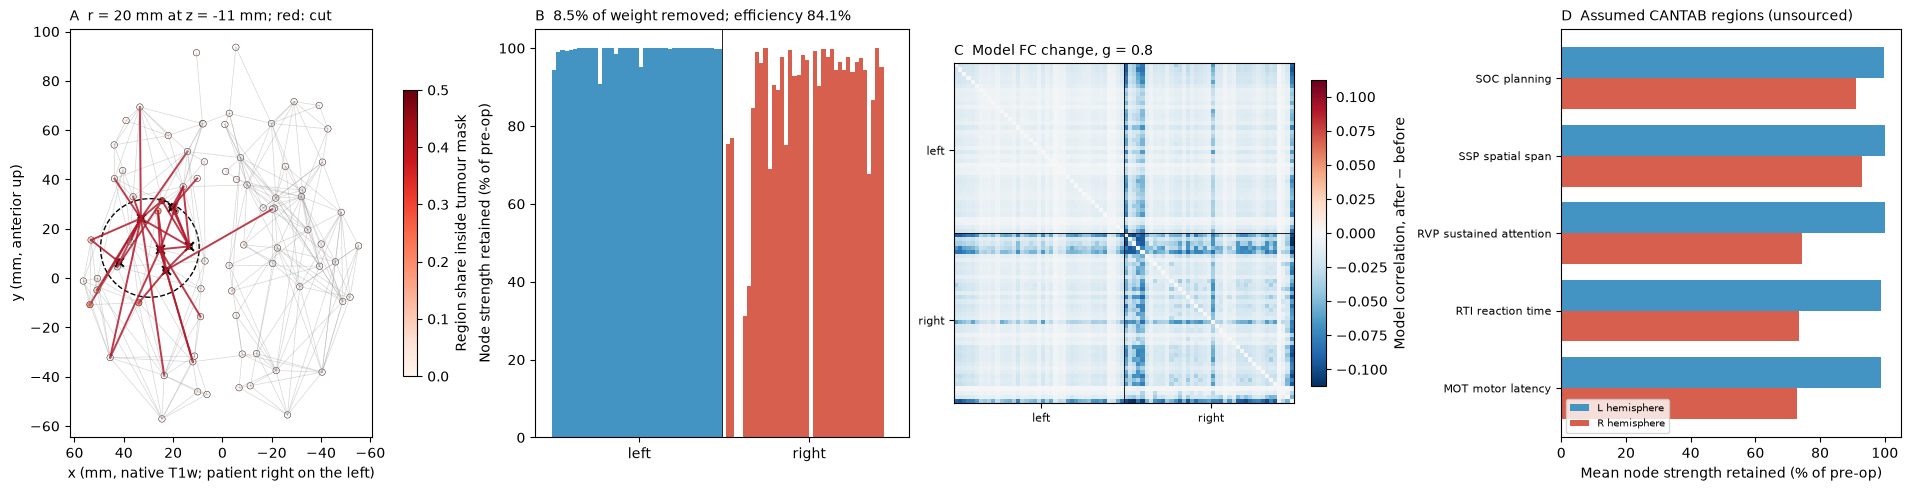

451 connected pairs cut; regions removed: R-Thalamus, R-Pallidum, R-Hippocampus, R-parahippocampal, R-transversetemporal, R-insula


In [8]:
import matplotlib.pyplot as plt

from glioma_ai.connectome_interactive import draw_scenario, resection_scenario

scenario = resection_scenario(case, TUMOUR_CENTRE, 20.0, coupling=0.8)
figure = plt.figure(figsize=(19, 4.8), constrained_layout=True)
draw_scenario(figure, case, scenario)
plt.show()
removed = [n for n, r in zip(case.names, scenario["removed"], strict=True) if r]
print(f"{scenario['pairs_cut']} connected pairs cut; regions removed: {', '.join(removed)}")

**Figure 3 | A 20 mm spherical virtual resection at the tumour-weighted centre, by geometric
proxy.** **A**, Axial view of region centroids as in Figure 2A, coloured by share inside the tumour
mask. The dashed circle is the sphere's outline in this projection (it is centred at the printed
$z$). Black crosses mark regions whose centroid is inside the sphere, and red lines are strong
pre-operative connections that the proxy cuts. **B**, Node strength retained by each region (% of
pre-operative), left hemisphere (blue) then right (red), in the order of Figure 1. **C**, Model FC
change (after − before) at $g=0.8$. **D**, Mean retained node strength over each assumed, unsourced
set of CANTAB regions, per hemisphere. Real pre-operative matrices, one patient; lesion by
geometric proxy; upstream QC pending.

**Neuro-oncology and clinical track.** Panel A should look familiar from Figure 2A: the proxy cuts the
same right temporal–insular–deep territory as the measured tumour-crossing streamlines, which is
what section 3.1 quantified. Panel B shows the disconnection idea of notebook 11 on real wiring.
Regions far from the sphere, including right frontal and parietal cortex, lose strength because some
of their connections pass through it. The left hemisphere loses at most about a tenth, in a few
medial regions whose straight segments to the right hemisphere cross the sphere. Panel D turns that
into "domain" bars, and here the caution matters most. The right-sided attention, reaction-time and
motor bars fall most only because the assumed table puts the insula, thalamus and putamen in those
sets. The five CANTAB measures of this release were not chosen for this tumour's location, and a
clinical neuropsychological assessment would normally be tailored to it.

**Data-analysis and modelling track.** Panel C shows only *decreases* in this scenario. Rows and
columns of removed regions drop to zero correlation, and their neighbours' correlations fall because
indirect paths are lost. Increases are possible in principle, because correlation is a ratio and a
node's variance can fall faster than its covariance with another. Compare the colour scale
with Figure 2C: the explorer's changes have the same small magnitude as the virtual resection's, an
order of magnitude below the measured FC changes. The model's sensitivity, not the lesion, limits
what panel C can show.

**Explore.** The dropdown sets the sphere's centre (the tumour-weighted centre or any region
centroid), the slider its radius, the checkbox whether straight segments through the sphere are cut,
and the second slider the coupling $g$. Things to try:
- At the tumour-weighted centre, raise $r$ from 0 to 40 mm. At what radius does the first region
  disappear, and when does the left hemisphere start to lose strength?
- Keep $r=15$ mm and move the centre from right superior temporal to right precentral to right
  rostral middle frontal. Which costs most weight, which most efficiency, and which changes the
  assumed SOC bar?
- Untick the segment proxy. The remaining damage is only the removed regions' own connections. How
  much of the effect at the tumour came from "cut fibres"?
- Set $g=0$: model FC becomes the identity and panel C goes blank, whatever the lesion. Raise $g$
  towards 0.95 and watch indirect effects spread.

**By track.** Clinical: choose a centre and radius that remove about the same weight as the tumour
mask (about 11%), but at a superficial cortical site. Do the assumed domain bars differ, and would
you trust that difference? Modelling: find two scenarios with the same weight removed but different
global efficiency, and explain the difference from panel A.

In [9]:
from glioma_ai.connectome_interactive import resection_explorer

resection_explorer()

interactive(children=(Dropdown(description='Sphere centre', layout=Layout(width='38em'), options=('Tumour-weig…

### 3.4 The same patient's CANTAB scores

Notebook 10 verifies this patient's five CANTAB measures against the OSF release. When the same
explicit local inputs are present, the cell below prints them for both visits. In Colab they
are absent and the cell prints a notice; notebook 10 shows the scores there from the OpenNeuro
tables. No mapping from
regions or connections to these measures is assumed, so no network quantity is compared with them.
The explorer's domain bars above are not compared with these scores either: they rest on an
assumed table and a geometric proxy, and the patient's actual resection is not known here.

In [10]:
from glioma_ai.cantab import read_release, verified_case

release_dir = Path(os.environ.get("CANTAB_OSF_DIR", ROOT / "data/cantab/osf"))
case_config = Path(os.environ.get("CANTAB_CASE_CONFIG", ROOT / "local/cantab-case.json"))
if (release_dir / "Data.csv").is_file() and case_config.is_file():
    config = json.loads(case_config.read_text())
    sessions = Path(config["sessions_path"])
    if not sessions.is_absolute():
        sessions = case_config.resolve().parent / sessions
    scores = verified_case(read_release(release_dir), sessions, config["source_case_id"])
    print(f"Assessment interval: {scores['assessment_interval_days']} days")
    for measure, value in scores["scores"].items():
        print(
            f"  {measure:<20} before {value['released_text'][0]:>8}   "
            f"follow-up {value['released_text'][1]:>8}   ({value['unit']})"
        )
    print("Interpretation:", scores["interpretation"])
else:
    print(
        "CANTAB not shown: run make cantab-fetch and supply local/cantab-case.json (notebook 10)."
    )

Assessment interval: 246 days
  MOT_latency_mean     before    817.8   follow-up    844.5   (ms)
  RTI_fiveRT           before    361.5   follow-up      327   (ms)
  RVP_A                before     0.95   follow-up     0.95   (A prime)
  SOC_prob_minmoves    before        8   follow-up        8   (problems)
  SSP_spanlength       before        6   follow-up        7   (span)
Interpretation: descriptive at release precision; reliable change not assessed


Read these scores as notebook 10 does: descriptive at release precision, with no reliable
change assessed and no causal attribution to surgery. A network-to-cognition comparison needs a
sourced mapping from measures to regions or networks and many patients, and it must be specified
before looking at the outcome.

**Neuro-oncology and clinical track.** One patient's two visits cannot separate the effects of the
tumour, the operation, adjuvant treatment, medication, fatigue, mood and practice on the second
testing. Recovery after glioma surgery also has its own time course, often over three to six months.
The measured change in structural weight was small (Figure 2B), so the explorer's large virtual
losses are not a description of this patient.

**Data-analysis and modelling track.** A test of "network damage predicts cognitive change" needs, at
minimum, a prespecified mapping, a reliable-change model with test–retest variance, and held-out
evaluation across patients. [Smolders et al. (2025)](https://doi.org/10.1093/braincomms/fcaf346) is
an example of the cohort-level design, with permutation-tested classifiers in 63 patients. With
$n=1$, none of that is available.

## 4. Speculation: connectomes, brain waves and analog cognition

**Evidence status: hypothesis.** Nothing in this section is computed from sub-PAT16, fitted or
tested. It sets the structural and functional connectomes of sections 1–3 beside a theoretical
framework of cognition and consciousness, to ask what such a framework would need from connectomics
and what connectomics cannot give it. Notebook 08 covers the measurement side: what an electrode
records, and what is needed before a field can be said to act on cells.

### 4.1 The framework of Miller, Brincat and Roy (2026)

[Miller, Brincat and Roy (2026)](https://doi.org/10.1523/JNEUROSCI.0711-26.2026) propose a *hybrid
synapse/wave* account. Their argument draws mainly on recordings in non-human primates:
- **Synapses store, waves control.** Synaptic connections, shaped by experience, store long-term
  information and define which activity patterns are possible. Brain waves, oscillating electric
  fields coordinated over millimetres to centimetres, act as a fast executive-like control process.
  It organises millions of neurons into lower-dimensional patterns in real time.
- **Mixed selectivity.** Many cortical neurons respond to nonlinear combinations of stimuli, context
  and actions rather than to one feature
  ([Rigotti et al. 2013](https://doi.org/10.1038/nature12160);
  [Tye et al. 2024](https://doi.org/10.1016/j.neuron.2024.04.017)). That makes them multifunctional,
  and a control system must route signals through overlapping networks.
- **Oscillations organise and route.** Gamma (about 30–80 Hz) goes with feedforward processing and
  spiking in superficial layers. Alpha/beta (about 10–30 Hz) goes with feedback in deep layers, a
  laminar motif reported across species and areas
  ([Mendoza-Halliday et al. 2024](https://doi.org/10.1038/s41593-023-01554-7)). Rhythms can open
  windows for communication between areas ([Fries 2015](https://doi.org/10.1016/j.neuron.2015.09.034)).
- **Ephaptic coupling.** Extracellular fields change nearby neurons' membrane potentials without
  synapses ([Anastassiou et al. 2011](https://doi.org/10.1038/nn.2727)). Because fields spread at
  effectively electromagnetic speed, the authors propose that they can coordinate neighbourhoods
  faster than axonal conduction. Recent work includes a historical review
  ([Hunt and MacIver 2026](https://doi.org/10.3389/fnhum.2026.1747899)) and a finite-element model
  of ephaptic coupling ([Jæger and Tveito 2026](https://doi.org/10.3389/fncom.2026.1755548)).
- **Spatial computing.** Spatially patterned alpha/beta acts as an inhibitory "stencil" on the
  cortical sheet, and decides *where* gamma and spiking can express sensory content
  ([Lundqvist et al. 2023](https://doi.org/10.1038/s41467-023-36555-4)). In multi-electrode recordings
  from monkey lateral prefrontal cortex, alpha/beta encoded task information in spatial patterns that
  changed with task conditions and were inversely related to where sensory spiking was expressed.
  They also reflected misattributions of task conditions and correlated with trial-by-trial decisions
  ([Chen et al. 2026](https://doi.org/10.1016/j.cub.2025.11.072)). Related work in monkeys found the
  same neural subspaces reused, task by task, across compositionally related tasks
  ([Tafazoli et al. 2026](https://doi.org/10.1038/s41586-025-09805-2)).
- **Travelling waves change the code.** Waves sweep across cortex
  ([Muller et al. 2018](https://doi.org/10.1038/nrn.2018.20)). The authors propose that alpha/beta
  travelling waves move population activity between coding subspaces. After a distraction,
  state-space rotations that restored prefrontal population patterns corresponded to travelling
  waves ([Batabyal et al. 2026](https://doi.org/10.1162/JOCN.a.2410)). Working-memory readout in the
  frontal eye field varied with theta phase, consistent with a wave scanning across it
  ([Han et al. 2026](https://doi.org/10.1016/j.neuron.2025.09.031)). In humans, travelling waves have
  been linked to memory states ([Das et al. 2026](https://doi.org/10.1038/s41467-026-71386-z)) and to
  visual–frontal coordination in working memory
  ([Luo and Ester 2025](https://doi.org/10.1073/pnas.2415573122)).
- **Analog computation.** Waves superpose. Two control signals, each a wave pattern, sum to a pattern
  unique to their combination. The authors compare this to analog computers that solve equations
  in parallel through physics, at low energy cost.
- **Consciousness.** Propofol, ketamine and dexmedetomidine act on different molecular targets.
  In intracortical recordings, all three reduced the stability of population dynamics, most in the
  low-frequency band ([Eisen et al. 2026](https://doi.org/10.1016/j.celrep.2026.117048); see also
  [Bardon et al. 2025](https://doi.org/10.1016/j.celrep.2025.115685)). The authors read this as
  consciousness depending on the integrity of large-scale wave organisation.

The article is a theoretical perspective. Its claims about consciousness are proposals, and it
relates them to global workspace, integrated information and higher-order theories. Whether
oscillations are a computational mechanism or an epiphenomenon is itself debated
([Singer and Effenberger 2025](https://doi.org/10.1007/s42087-025-00478-x)).

### 4.2 Where structural and functional connectomes meet this framework

| What the framework needs | What dMRI structural connectivity gives | What resting-state fMRI FC gives | What this notebook has |
| --- | --- | --- | --- |
| Synaptic scaffold that stores patterns | Macroscale bundles between centimetre-sized regions; no synapses, no direction, no sign | Nothing directly | 82 × 82 SIFT2 weights |
| Routes for long-range waves (theta/delta, area scale) | Candidate conduits and, with streamline lengths, conduction delays | Slow correlations that may partly reflect wave-borne coordination | Weights only; streamline lengths not tracked |
| Alpha/beta "stencils" over a few millimetres | Far below parcel scale | Far below spatial and temporal resolution | Nothing |
| Phase, frequency, direction of travelling waves | Constrains them in models only | BOLD at TR 2.4 s, 0.01–0.1 Hz: no alpha/beta/gamma phase | Nothing |
| Ephaptic fields | Fibre bundles where field effects on conduction have been modelled ([Schmidt et al. 2021](https://doi.org/10.1371/journal.pcbi.1007858)) | Nothing | Nothing (notebook 08 treats potentials and fields) |
| Integrity of global organisation | Efficiency, strength, interhemispheric weight (sections 1–3) | Homotopic and network FC | Both, at one resting state per session |

Three bridges between the two levels already exist, and they are why the speculation is not idle:
- *Connectome topology can direct waves in models.* In a cortical network model, gradients of
  incoming structural strength set the direction of travelling waves and frequency gradients, and the
  model fitted resting-state MEG FC best where those waves emerged
  ([Koller et al. 2024](https://doi.org/10.1038/s41467-024-47860-x)).
- *Geometry can matter more than the connectome.* Eigenmodes of the cortical surface explained fMRI
  activity patterns more parsimoniously than eigenmodes of the connectome, which fits a picture of
  waves on a continuous sheet ([Pang et al. 2023](https://doi.org/10.1038/s41586-023-06098-1)). A
  resection changes both the sheet and the wiring.
- *Wiring alone underdetermines dynamics.* In connectome-constrained network models, many parameter
  sets fit the same wiring, and recordings of a small subset of units remove the ambiguity
  ([Beiran and Litwin-Kumar 2025](https://doi.org/10.1038/s41593-025-02080-4)). Section 1's weak
  structure–function agreement is a macroscale cousin of that result.

In glioma, the network literature points the same way, as associations in cohorts, not tests of the
framework. Gliomas remodel neural circuits, and neuron–glioma interactions alter excitability
([Krishna et al. 2023](https://doi.org/10.1038/s41586-023-06036-1);
[Monje 2025](https://doi.org/10.1016/j.neuron.2025.07.012)). Fitting an oscillator model to glioma
patients' FC suggested stronger interregional interactions
([Alexandersen et al. 2025](https://doi.org/10.1162/netn_a_00426)). In 37 patients, resting MEG
activity in the frontoparietal network and around the tumour was not associated with executive
functioning ([Zimmermann et al. 2025](https://doi.org/10.1093/noajnl/vdaf168)), and the authors pointed
to network organisation instead. In 50 survivors more than a year after therapy, whole-brain
clustering (a measure of functional segregation) was higher than in controls and correlated with
intelligence and executive-function scores
([De Roeck et al. 2025](https://doi.org/10.1162/netn_a_00449)).

### 4.3 What it could mean, by track

**Neuro-oncology and clinical track.** If cognition depends on wave-borne coordination as much as on
which regions survive, three clinical intuitions would shift, as hypotheses:
- *Tracts as timing infrastructure.* Long association and commissural bundles would matter not only
  for carrying content but for keeping distant regions in phase. Cutting them could degrade
  coordination, for example homotopic coupling, beyond what the lost weight suggests. In this
  patient, homotopic FC was essentially unchanged after surgery (section 1 table). For one case and
  at BOLD timescales, that gives this idea no support.
- *A small structural change is not proof of a small functional change.* Figure 2B shows little
  measured structural loss. Under this framework, the relevant post-operative measurement would be
  oscillatory organisation (MEG, EEG, or ECoG during awake surgery), which this dataset does not have.
- *Mixed selectivity weakens lesion-to-test maps.* If prefrontal and parietal neurons are
  multifunctional and routed by context, a deficit after resection would depend on whether control
  signals can re-route, not only on which region was removed. This is one more reason the assumed
  table of section 3 cannot be trusted, and one possible account of recovery over months.

None of this is established in glioma patients. The anaesthesia findings concern unconsciousness in
animals, not recovery from surgery.

**Data-analysis and modelling track.** The linear model of sections 1–3 has no oscillation, no delay
and no space within a region, so it cannot represent any of these mechanisms. A next model, proposed
work only, would put phase oscillators or neural masses on the patient connectome with conduction
delays, for example

$$\dot\theta_i=\omega_i+K\sum_j W_{ij}\sin\!\big(\theta_j(t-\tau_{ij})-\theta_i(t)\big),\qquad \tau_{ij}=L_{ij}/v,$$

with $L_{ij}$ the mean streamline length (mm) and $v$ a conduction speed (m/s). That requires
re-deriving lengths from the tractograms (`make pat16-connectome`), choosing $v$ and frequencies
from the literature, and fitting to electrophysiology rather than BOLD. A neural-field model on the
cortical surface ([Pang et al. 2023](https://doi.org/10.1038/s41586-023-06098-1)) would need the
FreeSurfer surfaces, whose QC is pending. An ephaptic term would be local, below parcel scale, and
needs the measurement chain of notebook 08 before it can be parameterised.

### 4.4 Testable predictions (proposed work)

Each would need data this repository does not hold; none is a claim about sub-PAT16.
1. *Wave direction after disconnection.* In a connectome-constrained oscillator model, a virtual
   resection that removes incoming strength from a region should change local travelling-wave
   direction more than its mean FC. Test against pre- and post-operative MEG in a cohort that has both.
2. *Stencils near infiltrated cortex.* If spatial computing holds in humans, alpha/beta patterns
   across tumour-infiltrated cortex should be less task-specific than across normal cortex. Test with
   intraoperative ECoG or high-density probes during awake mapping.
3. *Coordination predicts cognition beyond structure.* Post-operative oscillatory organisation (for
   example homotopic phase synchrony) should predict CANTAB change beyond the structural loss. Test
   with a prespecified model and held-out patients.

## 5. Limits and next steps

**Data and processing**
1. **Review the upstream QC first.** Until the checklist is worked through, every number here is
   provisional. Re-derive with `make pat16-connectome` after any upstream change. The provenance
   hashes will change.
2. **Use the actual cavity.** Map the post-operative cavity into pre-operative space with the
   existing deformable registration and repeat the virtual resection with it. Report how much of
   the tumour mask it covers.
3. **Bound measurement variability.** Without repeat scans, compare the change in tumour-crossing
   connections with the change in connections far from the tumour. Better, add more patients from
   ds001226/ds002080: the cohort has 25 patients pre-operatively.
4. **Explain the interhemispheric difference between sessions.** The several-fold change in the
   interhemispheric share of structural weight (section 1) is unlikely to be surgical. Check tracking
   seeds, masks and the corpus-callosum handling in both sessions before interpreting any structural
   change.

**Model and explorer**

5. **Model choices.** Try $\log$ versus raw or normalised weights, global-signal regression of
   the measured FC, homotopic coupling and a nonlinear model. Report every variant, not the best one.
6. **Replace the sphere proxy.** Run the explorer's spheres through the tractograms, as the
   tumour mask was, and report recall and precision of the straight-segment proxy at many centres. Add
   a cortical-surface distance so superficial spheres do not cut deep fibres.
7. **Oscillations and delays (section 4).** Re-derive streamline lengths, add delays and an
   oscillator model, and fit it to electrophysiology, keeping the linear model as the baseline.
8. **Compare with notebook 11.** The synthetic network predicted that tracts through infiltrated
   white matter lose weight. This patient's measured change is much smaller. That gap is the
   teaching point.

**Cognition and clinical translation**

9. **A sourced, prespecified mapping.** Replace the assumed domain table with one taken from
   lesion–symptom or task-fMRI studies, register it before looking at outcomes, and estimate
   reliable change from test–retest data.
10. **Many patients and held-out evaluation.** A cohort design like
    [Smolders et al. (2025)](https://doi.org/10.1093/braincomms/fcaf346) is the minimum for a
    network-to-cognition claim. Report against location-only and clinical-only baselines.
11. **Timing and confounders.** Record the interval to each assessment, adjuvant treatment,
    antiseizure medication and recovery trajectory. After awake surgery, many patients recover within
    three to six months ([Amores-Carrera et al. 2025](https://doi.org/10.1093/nop/npaf075)).
12. **Clinical-state validation and harmonised protocols.** Patient-level use of glioma connectivity
    maps should wait until the clinical state of each scan is recorded and the map's added value is
    validated ([Kong and Wei 2026](https://doi.org/10.1002/nbm.70391)). Multi-centre work should
    follow harmonised acquisition recommendations
    ([Berger et al. 2026](https://doi.org/10.1111/ene.70708)).

**What each track can do next.** *Neuro-oncology and clinical:* write down, before seeing any result,
which tracts and which CANTAB measures you would expect to change after a right temporal–insular
resection, and why. That list is the prespecified mapping item 9 needs. *Data-analysis and
modelling:* implement item 6 on the tractograms and report the calibration table, then item 5's
variants, each with the placement null of Figure 2D.

**Reproducibility:** figures (`pat16_connectome`, `pat16_resection` as PNG/PDF) and
`pat16_connectome.json`, which holds every summary value, are written to ignored
`outputs/notebook12/`. Figure 3 and the tables of section 3 are recomputed in the notebook from the
tracked matrices. Rebuilding is deterministic and calls no language model.

## 6. References

Recent work (2025–2026) is marked ★. On 15 October 2026 every DOI below resolved in Crossref with the
cited title, first author, journal and year. Summaries in the text follow the PubMed or publisher
abstracts; the summaries of Herbet, Tykocki, Noll, Kong, Berger, Douw, Salvalaggio and Cayuela were
checked for notebooks 10 and 11. Nothing below is a result of this notebook.

**Data and methods used here**
- Aerts H et al. Modeling brain dynamics in brain tumor patients using The Virtual Brain. *eNeuro* 2018;5:ENEURO.0083-18.2018. [doi:10.1523/ENEURO.0083-18.2018](https://doi.org/10.1523/ENEURO.0083-18.2018)
- Aerts H et al. Modeling brain dynamics after tumor resection using The Virtual Brain. *NeuroImage* 2020;213:116738. [doi:10.1016/j.neuroimage.2020.116738](https://doi.org/10.1016/j.neuroimage.2020.116738)
- Aerts H et al. Pre- and post-surgery brain tumor multimodal magnetic resonance imaging data optimized for large scale computational modelling. *Sci Data* 2022;9:676. [doi:10.1038/s41597-022-01806-4](https://doi.org/10.1038/s41597-022-01806-4)
- Smith RE et al. SIFT2: enabling dense quantitative assessment of brain white matter connectivity using streamlines tractography. *NeuroImage* 2015;119:338–351. [doi:10.1016/j.neuroimage.2015.06.092](https://doi.org/10.1016/j.neuroimage.2015.06.092)
- Desikan RS et al. An automated labeling system for subdividing the human cerebral cortex on MRI scans into gyral based regions of interest. *NeuroImage* 2006;31:968–980. [doi:10.1016/j.neuroimage.2006.01.021](https://doi.org/10.1016/j.neuroimage.2006.01.021)
- Honey CJ et al. Predicting human resting-state functional connectivity from structural connectivity. *Proc Natl Acad Sci USA* 2009;106:2035–2040. [doi:10.1073/pnas.0811168106](https://doi.org/10.1073/pnas.0811168106)
- Latora V, Marchiori M. Efficient behavior of small-world networks. *Phys Rev Lett* 2001;87:198701. [doi:10.1103/PhysRevLett.87.198701](https://doi.org/10.1103/PhysRevLett.87.198701)

**Neuro-oncology and clinical track**
- Herbet G. Predictors of cognition after glioma surgery: connectotomy, structure-function phenotype, plasticity. *Brain* 2024;147:2621–2635. [doi:10.1093/brain/awae093](https://doi.org/10.1093/brain/awae093)
- ★ Tykocki T, Rakasz Ł. Connectome-guided glioma resection: a systematic review of white matter tract preservation and postoperative neurocognition. *Neurosurg Rev* 2026;49:191. [doi:10.1007/s10143-025-04081-0](https://doi.org/10.1007/s10143-025-04081-0)
- ★ Smolders L et al. Presurgical structural connectivity predicts postsurgical cognitive impairment in glioma patients. *Brain Commun* 2025;7:fcaf346. [doi:10.1093/braincomms/fcaf346](https://doi.org/10.1093/braincomms/fcaf346)
- ★ Muir M et al. Resectability of white matter tracts in patients with language-critical gliomas. *Neurosurgery* 2026;99:140–148 (online 2025). [doi:10.1227/neu.0000000000003792](https://doi.org/10.1227/neu.0000000000003792)
- ★ Vargas LO et al. Extent of resection, cognition, and health-related quality of life after adult glioma surgery: a systematic review. *J Clin Neurosci* 2026;150:112064. [doi:10.1016/j.jocn.2026.112064](https://doi.org/10.1016/j.jocn.2026.112064)
- ★ Amores-Carrera L et al. Neuropsychological outcomes following awake surgery in adult glioma patients: a systematic review. *Neuro-Oncol Pract* 2026;13:23–47 (online 2025). [doi:10.1093/nop/npaf075](https://doi.org/10.1093/nop/npaf075)
- ★ Noll KR et al. Changes in functional connectivity are associated with functional independence in the early postoperative period following awake surgical resection of language-eloquent glioma. *Neuro-Oncol Adv* 2025;7:vdaf192. [doi:10.1093/noajnl/vdaf192](https://doi.org/10.1093/noajnl/vdaf192)
- ★ Colpo M et al. Structural-functional fingerprinting for abnormalities investigation in glioma patients. *Sci Rep* 2025;15:38404. [doi:10.1038/s41598-025-22192-y](https://doi.org/10.1038/s41598-025-22192-y)
- ★ Zimmermann MLM et al. The relationship between deviant brain activity and executive functioning in glioma patients. *Neuro-Oncol Adv* 2025;7:vdaf168. [doi:10.1093/noajnl/vdaf168](https://doi.org/10.1093/noajnl/vdaf168)
- ★ De Roeck L et al. Increased functional network segregation in glioma patients posttherapy: a neurological compensatory response or catastrophe for cognition? *Netw Neurosci* 2025;9:743–760. [doi:10.1162/netn_a_00449](https://doi.org/10.1162/netn_a_00449)
- ★ Kong SS, Wei LC. Clinical-state validation should precede patient-level use of glioma connectivity anomaly maps. *NMR Biomed* 2026;39:e70391. [doi:10.1002/nbm.70391](https://doi.org/10.1002/nbm.70391)
- ★ Berger T et al. Harmonized acquisition of connectome MRI and clinical data for stroke, Parkinson's disease and glioma: Delphi-derived protocol recommendations by the European Academy of Neurology. *Eur J Neurol* 2026;33:e70708. [doi:10.1111/ene.70708](https://doi.org/10.1111/ene.70708)
- ★ Douw L et al. Multiscale network perspectives on glioma: from tumour biology to symptoms, survival and treatment. *Nat Rev Neurol* 2026;22:73–89. [doi:10.1038/s41582-025-01171-x](https://doi.org/10.1038/s41582-025-01171-x)
- ★ Salvalaggio A et al. Insights from the brain connectome in patients with gliomas. *Curr Opin Oncol* 2025;37:595–602. [doi:10.1097/CCO.0000000000001190](https://doi.org/10.1097/CCO.0000000000001190)
- ★ Cayuela N et al. Mapping glioma's impact on cognition: insights from macrostructure, microstructure, and beyond. *Neuro-Oncol Adv* 2025;7:vdaf003. [doi:10.1093/noajnl/vdaf003](https://doi.org/10.1093/noajnl/vdaf003)

**Data-analysis and modelling track**
- Alstott J et al. Modeling the impact of lesions in the human brain. *PLoS Comput Biol* 2009;5:e1000408. [doi:10.1371/journal.pcbi.1000408](https://doi.org/10.1371/journal.pcbi.1000408)
- ★ Alexandersen CG et al. Functional connectotomy of a whole-brain model reveals tumor-induced alterations to neuronal dynamics in glioma patients. *Netw Neurosci* 2025;9:280–302. [doi:10.1162/netn_a_00426](https://doi.org/10.1162/netn_a_00426)
- ★ Beiran M, Litwin-Kumar A. Prediction of neural activity in connectome-constrained recurrent networks. *Nat Neurosci* 2025;28:2561–2574. [doi:10.1038/s41593-025-02080-4](https://doi.org/10.1038/s41593-025-02080-4)
- Pang JC et al. Geometric constraints on human brain function. *Nature* 2023;618:566–574. [doi:10.1038/s41586-023-06098-1](https://doi.org/10.1038/s41586-023-06098-1)
- Koller DP, Schirner M, Ritter P. Human connectome topology directs cortical traveling waves and shapes frequency gradients. *Nat Commun* 2024;15:3570. [doi:10.1038/s41467-024-47860-x](https://doi.org/10.1038/s41467-024-47860-x)
- Schmidt H et al. Ephaptic coupling in white matter fibre bundles modulates axonal transmission delays. *PLoS Comput Biol* 2021;17:e1007858. [doi:10.1371/journal.pcbi.1007858](https://doi.org/10.1371/journal.pcbi.1007858)

**Section 4: waves, fields and cognition (speculative framework)**
- ★ Miller EK, Brincat SL, Roy JE. Analog cognition and consciousness. *J Neurosci* 2026;46:e0711262026. [doi:10.1523/JNEUROSCI.0711-26.2026](https://doi.org/10.1523/JNEUROSCI.0711-26.2026)
- Rigotti M et al. The importance of mixed selectivity in complex cognitive tasks. *Nature* 2013;497:585–590. [doi:10.1038/nature12160](https://doi.org/10.1038/nature12160)
- Tye KM et al. Mixed selectivity: cellular computations for complexity. *Neuron* 2024;112:2289–2303. [doi:10.1016/j.neuron.2024.04.017](https://doi.org/10.1016/j.neuron.2024.04.017)
- Fries P. Rhythms for cognition: communication through coherence. *Neuron* 2015;88:220–235. [doi:10.1016/j.neuron.2015.09.034](https://doi.org/10.1016/j.neuron.2015.09.034)
- Mendoza-Halliday D et al. A ubiquitous spectrolaminar motif of local field potential power across the primate cortex. *Nat Neurosci* 2024;27:547–560. [doi:10.1038/s41593-023-01554-7](https://doi.org/10.1038/s41593-023-01554-7)
- Anastassiou CA et al. Ephaptic coupling of cortical neurons. *Nat Neurosci* 2011;14:217–223. [doi:10.1038/nn.2727](https://doi.org/10.1038/nn.2727)
- ★ Hunt T, MacIver MB. A historical review of ephaptic field research: from early foundations through contemporary renaissance. *Front Hum Neurosci* 2026;20:1747899. [doi:10.3389/fnhum.2026.1747899](https://doi.org/10.3389/fnhum.2026.1747899)
- ★ Jæger KH, Tveito A. Extracellular stimulation and ephaptic coupling of neurons in a fully coupled finite element-based Extracellular–Membrane–Intracellular (EMI) model. *Front Comput Neurosci* 2026;20:1755548. [doi:10.3389/fncom.2026.1755548](https://doi.org/10.3389/fncom.2026.1755548)
- Lundqvist M et al. Working memory control dynamics follow principles of spatial computing. *Nat Commun* 2023;14:1429. [doi:10.1038/s41467-023-36555-4](https://doi.org/10.1038/s41467-023-36555-4)
- ★ Chen Z et al. Oscillatory control of cortical space as a computational dimension. *Curr Biol* 2026;36:402–414. [doi:10.1016/j.cub.2025.11.072](https://doi.org/10.1016/j.cub.2025.11.072)
- Muller L et al. Cortical travelling waves: mechanisms and computational principles. *Nat Rev Neurosci* 2018;19:255–268. [doi:10.1038/nrn.2018.20](https://doi.org/10.1038/nrn.2018.20)
- ★ Batabyal T et al. State–space trajectories and traveling waves following distraction. *J Cogn Neurosci* 2026;38:695–715. [doi:10.1162/JOCN.a.2410](https://doi.org/10.1162/JOCN.a.2410)
- ★ Han H-B et al. Working memory readout varies with frontal theta rhythms. *Neuron* 2026;114:159–166. [doi:10.1016/j.neuron.2025.09.031](https://doi.org/10.1016/j.neuron.2025.09.031)
- ★ Das A et al. Planar, spiral, and concentric traveling waves distinguish behavioral states in human memory. *Nat Commun* 2026;17:5143. [doi:10.1038/s41467-026-71386-z](https://doi.org/10.1038/s41467-026-71386-z)
- ★ Luo C, Ester EF. Traveling waves link human visual and frontal cortex during working memory–guided behavior. *Proc Natl Acad Sci USA* 2025;122:e2415573122. [doi:10.1073/pnas.2415573122](https://doi.org/10.1073/pnas.2415573122)
- ★ Tafazoli S et al. Building compositional tasks with shared neural subspaces. *Nature* 2026;650:164–172. [doi:10.1038/s41586-025-09805-2](https://doi.org/10.1038/s41586-025-09805-2)
- ★ Eisen AJ et al. Similar destabilization of neural dynamics under different general anesthetics. *Cell Rep* 2026;45:117048. [doi:10.1016/j.celrep.2026.117048](https://doi.org/10.1016/j.celrep.2026.117048)
- ★ Bardon AG et al. Convergent effects of different anesthetics on changes in phase alignment of cortical oscillations. *Cell Rep* 2025;44:115685. [doi:10.1016/j.celrep.2025.115685](https://doi.org/10.1016/j.celrep.2025.115685)
- ★ Singer W, Effenberger F. Oscillations in natural neuronal networks; an epiphenomenon or a fundamental computational mechanism? *Hum Arenas* 2025;8:846–868. [doi:10.1007/s42087-025-00478-x](https://doi.org/10.1007/s42087-025-00478-x)
- Krishna S et al. Glioblastoma remodelling of human neural circuits decreases survival. *Nature* 2023;617:599–607. [doi:10.1038/s41586-023-06036-1](https://doi.org/10.1038/s41586-023-06036-1)
- ★ Monje M. The neuroscience of brain cancers. *Neuron* 2025;113:2734–2739. [doi:10.1016/j.neuron.2025.07.012](https://doi.org/10.1016/j.neuron.2025.07.012)